# Klasifikasi Multilabel: Yeast Dataset

Dataset Yeast berisi profil ekspresi gen mikroarray dan profil filogenetik dari ragi (*Saccharomyces cerevisiae*). Satu protein sering kali terlibat dalam beberapa fungsi biologis secara simultan. Data ini bersumber dari repositori benchmark Mulan.

- Nama dataset: Yeast
- Sumber data: Mulan MLC Datasets Repository
- Link halaman resmi: http://mulan.sourceforge.net/datasets-mlc.html
- Link unduhan arsip: https://downloads.sourceforge.net/project/mulan/datasets/yeast.rar
- Dimensi data: 2.417 baris dan 117 kolom (103 fitur biologis dan 14 kolom label fungsional)
- Label target: `Class1` sampai `Class14` yang memetakan kategori fungsional protein MIPS

In [1]:
import os
import subprocess
import urllib.request
import tempfile
import pandas as pd
from scipy.io import arff

tmpdir = tempfile.gettempdir()
rar_path = os.path.join(tmpdir, "yeast.rar")
extract_dir = os.path.join(tmpdir, "yeast_extracted") + "/"
os.makedirs(extract_dir, exist_ok=True)

if not os.path.exists(rar_path):
    url = "https://downloads.sourceforge.net/project/mulan/datasets/yeast.rar"
    urllib.request.urlretrieve(url, rar_path)

subprocess.run(["unrar", "x", "-o+", rar_path, extract_dir], check=True, stdout=subprocess.DEVNULL)

arff_path = os.path.join(extract_dir, "yeast.arff")
data, meta = arff.loadarff(arff_path)
df = pd.DataFrame(data)

target_cols = meta.names()[-14:]
for col in target_cols:
    df[col] = df[col].astype(str).str.replace("b'", "").str.replace("'", "").astype(int)

print("Shape data:", df.shape)
display(df.head())
print("\nTipe data:")
print(df.dtypes)

Shape data: (2417, 117)


,Att1,Att2,Att3,Att4,Att5,Att6,Att7,Att8,Att9,Att10,...,Class5,Class6,Class7,Class8,Class9,Class10,Class11,Class12,Class13,Class14
0,0.004168,-0.170975,-0.156748,-0.142151,0.058781,0.026851,0.197719,0.041850,0.066938,-0.056617,...,0,0,1,1,0,0,0,1,1,0
1,-0.103956,0.011879,-0.098986,-0.054501,-0.007970,0.049113,-0.030580,-0.077933,-0.080529,-0.016267,...,0,0,0,0,0,0,0,0,0,0
2,0.509949,0.401709,0.293799,0.087714,0.011686,-0.006411,-0.006255,0.013646,-0.040666,-0.024447,...,0,0,0,0,0,0,0,1,1,0
3,0.119092,0.004412,-0.002262,0.072254,0.044512,-0.051467,0.074686,-0.007670,0.079438,0.062184,...,0,0,0,0,0,0,0,0,0,0
4,0.042037,0.007054,-0.069483,0.081015,-0.048207,0.089446,-0.004947,0.064456,-0.133387,0.068878,...,1,1,0,0,0,0,0,0,0,0



Tipe data:
Att1       float64
Att2       float64
Att3       float64
Att4       float64
Att5       float64
            ...   
Class10      int64
Class11      int64
Class12      int64
Class13      int64
Class14      int64
Length: 117, dtype: object


Jumlah label            : 14
Label cardinality       : 4.237  (rata-rata label per baris)
Label density           : 0.303
Baris dengan >1 label   : 98.7%
Baris tanpa label       : 0.0%
=> Multilabel


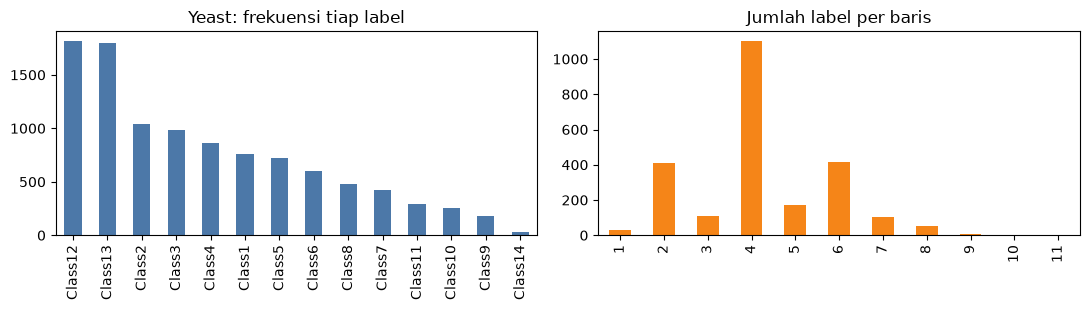

In [2]:
import matplotlib.pyplot as plt

def check_multilabel(Y, title):
    Y = pd.DataFrame(Y)
    per_row = Y.sum(axis=1)
    print(f"Jumlah label            : {Y.shape[1]}")
    print(f"Label cardinality       : {per_row.mean():.3f}  (rata-rata label per baris)")
    print(f"Label density           : {per_row.mean() / Y.shape[1]:.3f}")
    print(f"Baris dengan >1 label   : {(per_row > 1).mean():.1%}")
    print(f"Baris tanpa label       : {(per_row == 0).mean():.1%}")
    print("=> Multilabel" if (per_row > 1).any() else "=> Bukan multilabel (tidak ada baris dengan >1 label)")
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
    Y.sum().sort_values(ascending=False).plot(kind="bar", ax=axes[0], color="#4C78A8")
    axes[0].set_title(f"{title}: frekuensi tiap label")
    per_row.value_counts().sort_index().plot(kind="bar", ax=axes[1], color="#F58518")
    axes[1].set_title("Jumlah label per baris")
    plt.tight_layout()
    plt.show()

check_multilabel(df[target_cols], "Yeast")

In [3]:
assert len(target_cols) == 14, f"Jumlah label harus 14, didapat: {len(target_cols)}"
assert (df[target_cols].sum(axis=1) > 1).sum() > 0, "Harus terdapat baris dengan lebih dari 1 label"
assert df[target_cols].sum(axis=1).mean() > 1.0, "Label cardinality harus > 1.0"
assert df.shape == (2417, 117), f"Bentuk dataframe tidak sesuai: {df.shape}"

for col in target_cols:
    assert set(df[col].unique()).issubset({0, 1}), f"Kolom target {col} harus bernilai biner 0/1"

print("Semua verifikasi lolos.")

Semua verifikasi lolos.


## Kesimpulan

Dataset Yeast terbukti merupakan klasifikasi multilabel:
1. Target terbagi ke dalam 14 kolom kelas fungsional independen (`Class1` s.d. `Class14`).
2. Sebanyak 2.385 baris (98,68% dari total 2.417 baris) memiliki lebih dari 1 label aktif, dengan beberapa sampel memiliki hingga 11 label fungsional aktif.
3. Nilai label cardinality sebesar 4,2371 dengan label density 0,3026.
4. Tidak ada baris yang kosong dari label fungsional (0%).